In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')

In [2]:
from google.colab import files

uploaded = files.upload()

df = pd.read_csv(next(iter(uploaded)))

print("Ukuran Dataset:", df.shape)
df.head()

Saving paket_a_transaksi_pos_2024_2025 (1).csv to paket_a_transaksi_pos_2024_2025 (1).csv
Ukuran Dataset: (5030, 9)


,id_transaksi,tanggal,kode_gerai,kode_kasir,kode_produk,jumlah,harga_satuan,diskon_persen,status
0,TRX0241065,2025-06-02,G09,K011,RMT1402,4,13000,0,SELESAI
1,TRX0240510,2024-12-28,G09,K015,SGR1205,1,21000,0,SELESAI
2,TRX0244483,2024-09-04,G11,K029,RMT1407,3,"7500,00",0,SELESAI
3,TRX0242532,2025-07-30,G05,K001,MKN1103,2,6500,0,SELESAI
4,TRX0243509,26/03/2025,G05,K016,RMT1407,1,6000,0,SELESAI


In [3]:
df.info()

print("\nJumlah Data:", df.shape[0])
print("Jumlah Kolom:", df.shape[1])

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5030 entries, 0 to 5029
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   id_transaksi   5030 non-null   object
 1   tanggal        5030 non-null   object
 2   kode_gerai     5030 non-null   object
 3   kode_kasir     4769 non-null   object
 4   kode_produk    5030 non-null   object
 5   jumlah         5030 non-null   int64 
 6   harga_satuan   5030 non-null   object
 7   diskon_persen  5030 non-null   int64 
 8   status         5030 non-null   object
dtypes: int64(2), object(7)
memory usage: 353.8+ KB

Jumlah Data: 5030
Jumlah Kolom: 9


In [4]:
# Membuat salinan dataset
df_viz = df.copy()

# Mengubah format tanggal
df_viz['tanggal'] = pd.to_datetime(
    df_viz['tanggal'],
    format='mixed',
    dayfirst=True,
    errors='coerce'
)

# Mengubah harga menjadi numerik
df_viz['harga_satuan'] = pd.to_numeric(
    df_viz['harga_satuan'].astype(str).str.replace(',', '.', regex=False),
    errors='coerce'
)

# Mengubah jumlah negatif menjadi positif
df_viz['jumlah'] = df_viz['jumlah'].abs()

# Menghitung omzet kotor
df_viz['Total_Kotor'] = (
    df_viz['harga_satuan'] * df_viz['jumlah']
)

# Menghitung nominal diskon
df_viz['Nominal_Diskon'] = (
    df_viz['Total_Kotor'] * df_viz['diskon_persen'] / 100
)

# Menghitung omzet bersih
df_viz['Total_Bersih'] = (
    df_viz['Total_Kotor'] - df_viz['Nominal_Diskon']
) * 1.11

# Memeriksa hasil
df_viz.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5030 entries, 0 to 5029
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   id_transaksi    5030 non-null   object        
 1   tanggal         5030 non-null   datetime64[ns]
 2   kode_gerai      5030 non-null   object        
 3   kode_kasir      4769 non-null   object        
 4   kode_produk     5030 non-null   object        
 5   jumlah          5030 non-null   int64         
 6   harga_satuan    5030 non-null   float64       
 7   diskon_persen   5030 non-null   int64         
 8   status          5030 non-null   object        
 9   Total_Kotor     5030 non-null   float64       
 10  Nominal_Diskon  5030 non-null   float64       
 11  Total_Bersih    5030 non-null   float64       
dtypes: datetime64[ns](1), float64(4), int64(2), object(5)
memory usage: 471.7+ KB


In [5]:
# Mengambil data transaksi tahun 2025
df_2025 = df_viz.loc[
    df_viz['tanggal'].dt.year == 2025
].copy()

print("Jumlah transaksi tahun 2025:", len(df_2025))

display(df_2025.head())

Jumlah transaksi tahun 2025: 2523


,id_transaksi,tanggal,kode_gerai,kode_kasir,kode_produk,jumlah,harga_satuan,diskon_persen,status,Total_Kotor,Nominal_Diskon,Total_Bersih
0,TRX0241065,2025-06-02,G09,K011,RMT1402,4,13000.0,0,SELESAI,52000.0,0.0,57720.0
3,TRX0242532,2025-07-30,G05,K001,MKN1103,2,6500.0,0,SELESAI,13000.0,0.0,14430.0
4,TRX0243509,2025-03-26,G05,K016,RMT1407,1,6000.0,0,SELESAI,6000.0,0.0,6660.0
5,TRX0240658,2025-07-18,G01,K008,RMT1408,12,45500.0,10,SELESAI,546000.0,54600.0,545454.0
6,TRX0244581,2025-09-24,G10,K021,MIN1004,1,18000.0,0,SELESAI,18000.0,0.0,19980.0


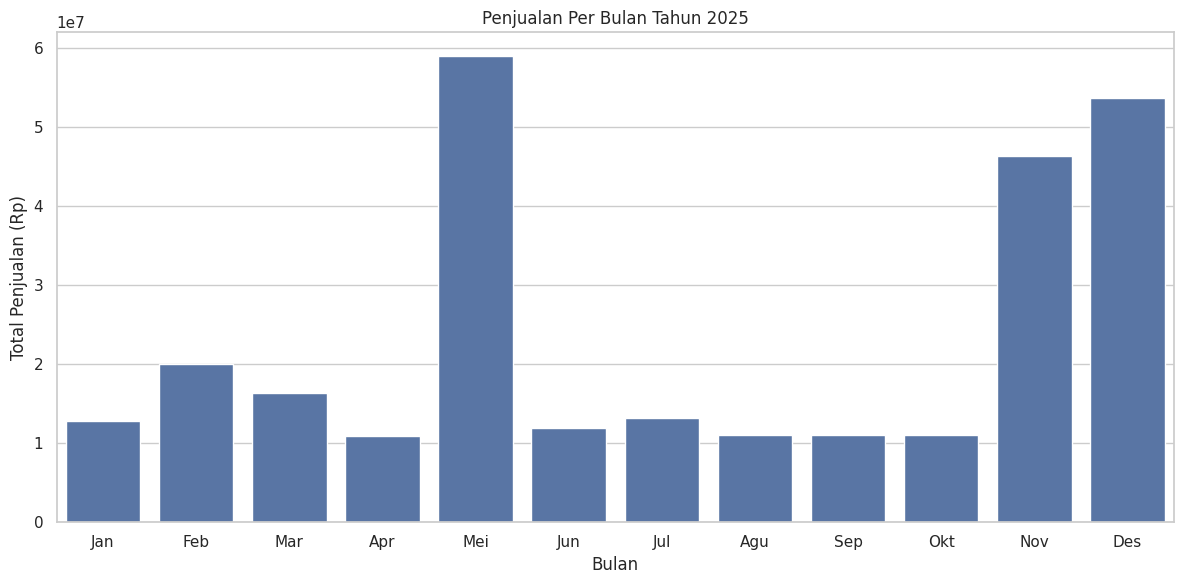

In [6]:
# Memfilter transaksi yang berhasil
penjualan_2025 = df_2025.loc[
    df_2025['status'] == 'SELESAI'
]

# Menghitung total penjualan setiap bulan
penjualan_bulanan = penjualan_2025.groupby(
    penjualan_2025['tanggal'].dt.month
)['Total_Bersih'].sum().reindex(range(1, 13), fill_value=0)

# Mengubah hasil menjadi DataFrame
data_bulanan = penjualan_bulanan.reset_index()
data_bulanan.columns = ['Bulan', 'Total_Penjualan']

# Memberikan nama bulan
nama_bulan = [
    'Jan', 'Feb', 'Mar', 'Apr', 'Mei', 'Jun',
    'Jul', 'Agu', 'Sep', 'Okt', 'Nov', 'Des'
]

data_bulanan['Nama_Bulan'] = nama_bulan

# Membuat visualisasi
plt.figure(figsize=(12, 6))

sns.barplot(
    data=data_bulanan,
    x='Nama_Bulan',
    y='Total_Penjualan'
)

plt.title('Penjualan Per Bulan Tahun 2025')
plt.xlabel('Bulan')
plt.ylabel('Total Penjualan (Rp)')

plt.tight_layout()
plt.show()

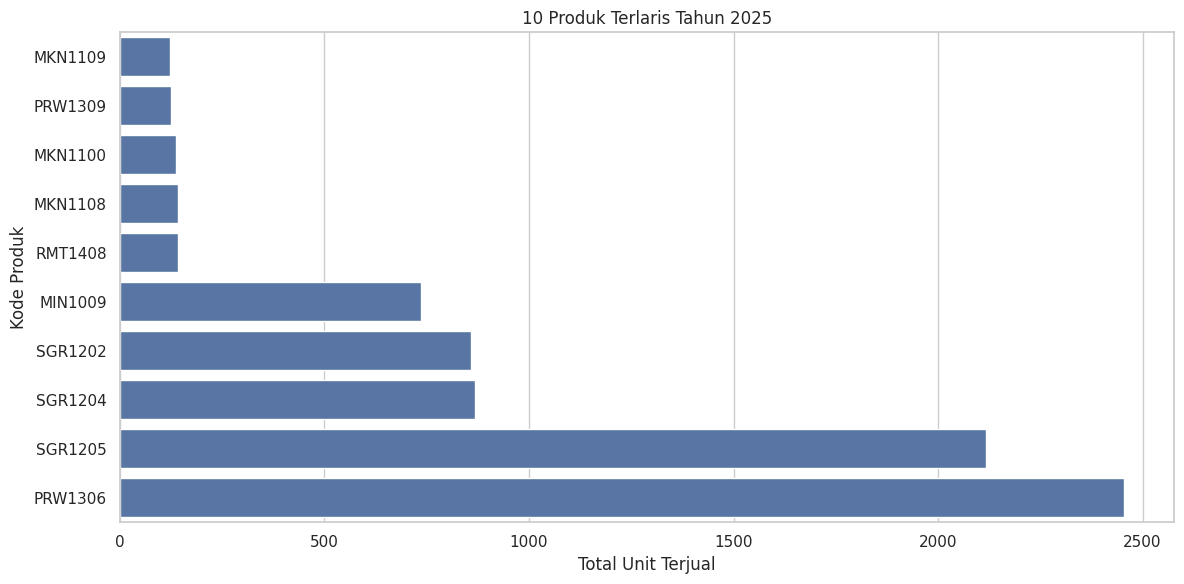

In [7]:
# Memfilter transaksi berhasil
produk_2025 = df_2025.loc[
    df_2025['status'] == 'SELESAI'
]

# Menghitung total unit terjual setiap produk
produk_terlaris = produk_2025.groupby(
    'kode_produk'
)['jumlah'].sum()

# Mengambil 10 produk terlaris
top_10_produk = produk_terlaris.nlargest(10).sort_values()

# Membuat visualisasi
plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_10_produk.values,
    y=top_10_produk.index
)

plt.title('10 Produk Terlaris Tahun 2025')
plt.xlabel('Total Unit Terjual')
plt.ylabel('Kode Produk')

plt.tight_layout()
plt.show()

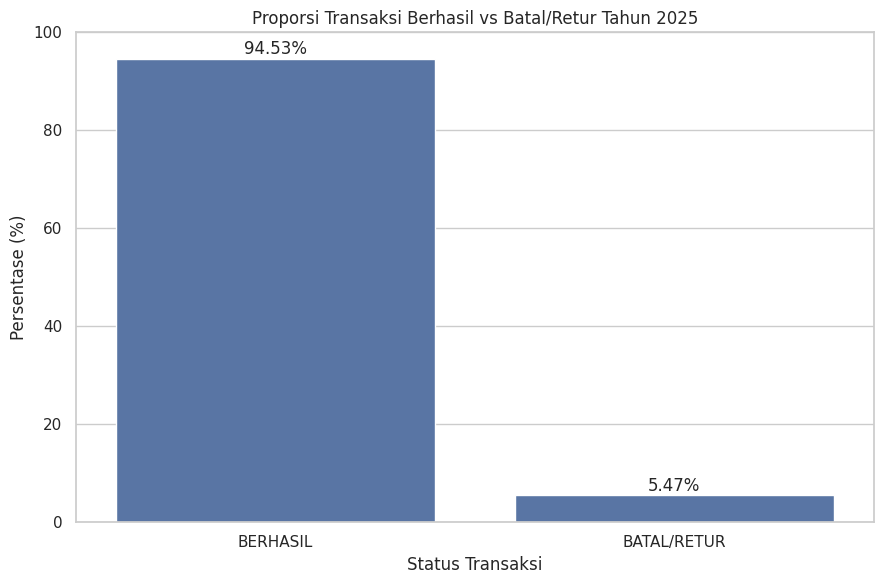

In [8]:
# Mengelompokkan status transaksi
df_2025['Kategori_Status'] = np.where(
    df_2025['status'] == 'SELESAI',
    'BERHASIL',
    'BATAL/RETUR'
)

# Menghitung jumlah transaksi setiap kategori
status_transaksi = df_2025['Kategori_Status'].value_counts()

# Menghitung persentase transaksi
persentase_status = (
    status_transaksi / status_transaksi.sum() * 100
).reset_index()

persentase_status.columns = ['Status', 'Persentase']

# Membuat visualisasi
plt.figure(figsize=(9, 6))

sns.barplot(
    data=persentase_status,
    x='Status',
    y='Persentase'
)

plt.title('Proporsi Transaksi Berhasil vs Batal/Retur Tahun 2025')
plt.xlabel('Status Transaksi')
plt.ylabel('Persentase (%)')

plt.ylim(0, 100)

for i, nilai in enumerate(persentase_status['Persentase']):
    plt.text(
        i,
        nilai + 1,
        f'{nilai:.2f}%',
        ha='center'
    )

plt.tight_layout()
plt.show()

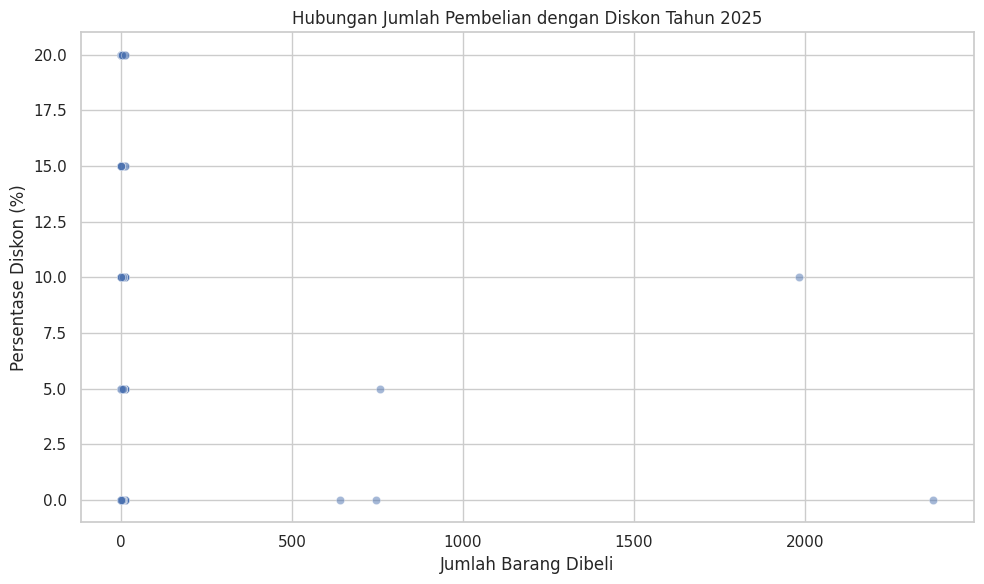

In [9]:
# Memfilter transaksi berhasil
data_diskon = df_2025.loc[
    df_2025['status'] == 'SELESAI'
]

# Membuat visualisasi
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=data_diskon,
    x='jumlah',
    y='diskon_persen',
    alpha=0.5
)

plt.title('Hubungan Jumlah Pembelian dengan Diskon Tahun 2025')
plt.xlabel('Jumlah Barang Dibeli')
plt.ylabel('Persentase Diskon (%)')

plt.tight_layout()
plt.show()

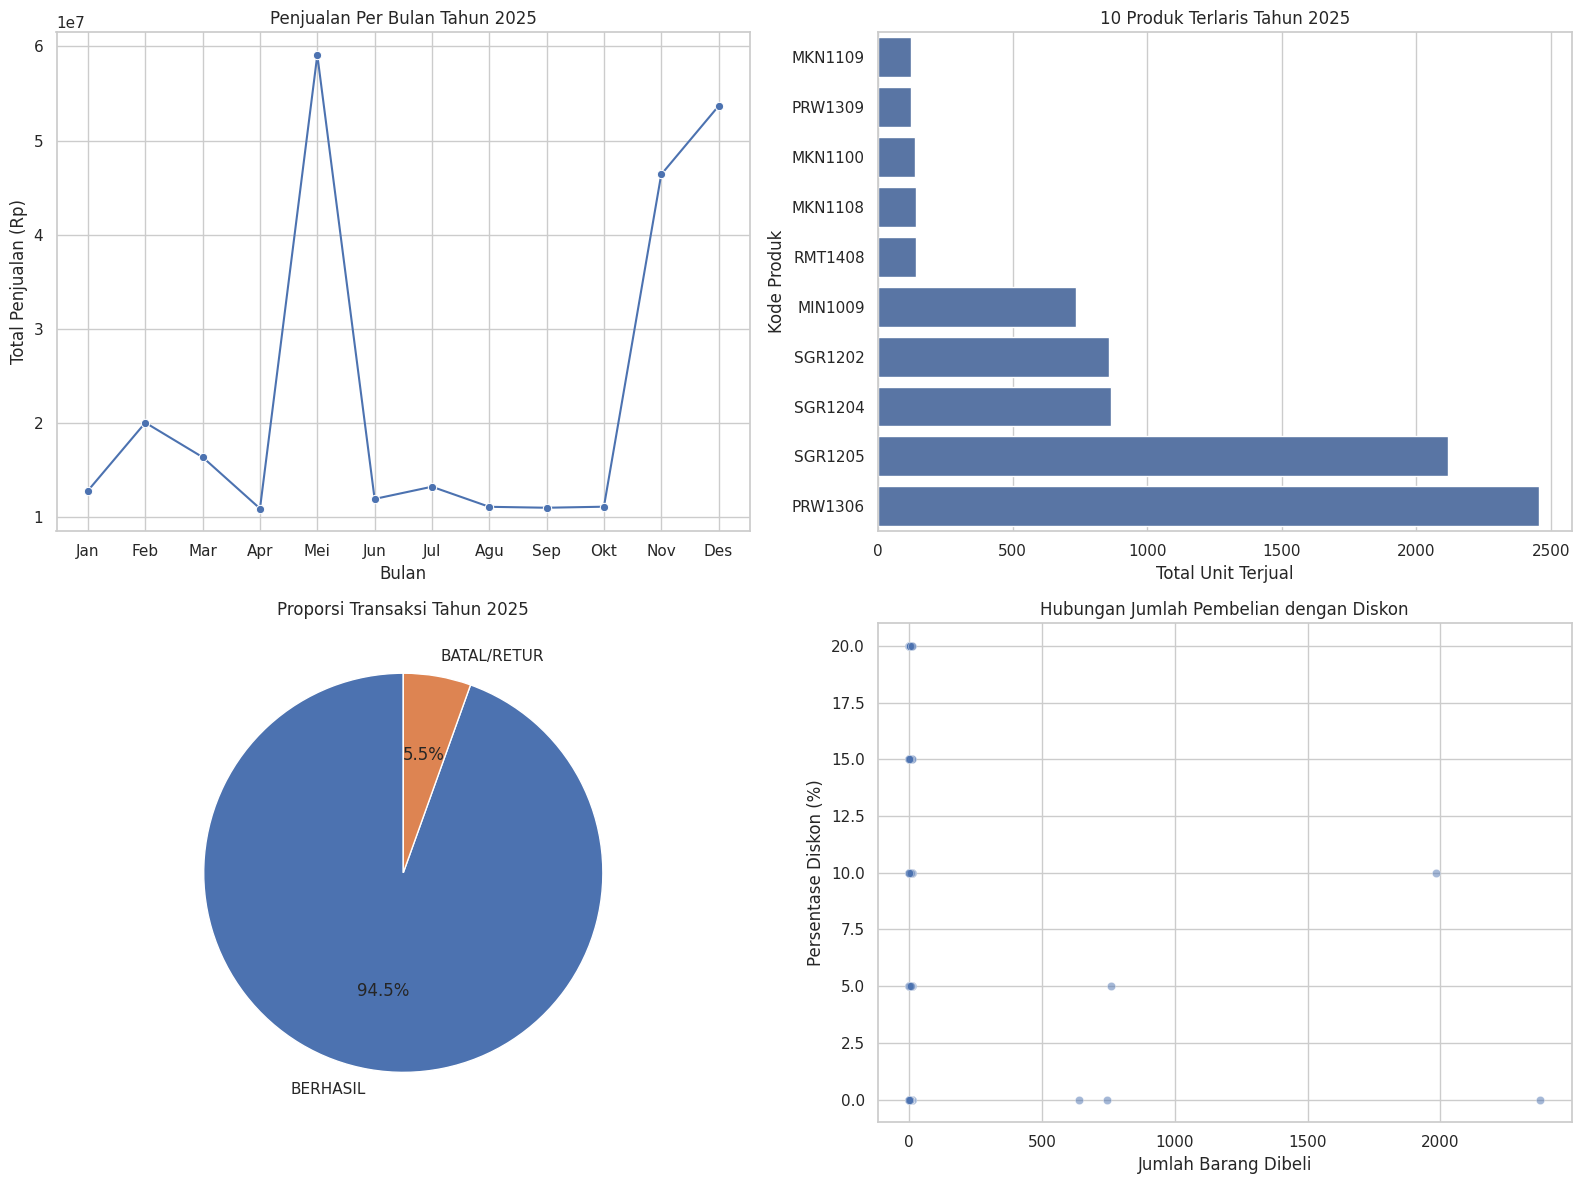

In [10]:
# Membuat figure dengan 4 kotak visualisasi
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Bagian 1: Penjualan per bulan
sns.lineplot(
    data=data_bulanan,
    x='Nama_Bulan',
    y='Total_Penjualan',
    marker='o',
    ax=axes[0, 0]
)

axes[0, 0].set_title('Penjualan Per Bulan Tahun 2025')
axes[0, 0].set_xlabel('Bulan')
axes[0, 0].set_ylabel('Total Penjualan (Rp)')

# Bagian 2: 10 produk terlaris
sns.barplot(
    x=top_10_produk.values,
    y=top_10_produk.index,
    ax=axes[0, 1]
)

axes[0, 1].set_title('10 Produk Terlaris Tahun 2025')
axes[0, 1].set_xlabel('Total Unit Terjual')
axes[0, 1].set_ylabel('Kode Produk')

# Bagian 3: Proporsi transaksi
axes[1, 0].pie(
    status_transaksi.values,
    labels=status_transaksi.index,
    autopct='%1.1f%%',
    startangle=90
)

axes[1, 0].set_title('Proporsi Transaksi Tahun 2025')

# Bagian 4: Hubungan jumlah beli dengan diskon
sns.scatterplot(
    data=data_diskon,
    x='jumlah',
    y='diskon_persen',
    alpha=0.5,
    ax=axes[1, 1]
)

axes[1, 1].set_title('Hubungan Jumlah Pembelian dengan Diskon')
axes[1, 1].set_xlabel('Jumlah Barang Dibeli')
axes[1, 1].set_ylabel('Persentase Diskon (%)')

# Mengatur jarak antar grafik
plt.tight_layout()
plt.show()